# Cohort Purification — GSE136103 (Human Healthy & Cirrhotic Liver scRNA-seq)
**Accession:** NCBI GEO `GSE136103` (Ramachandran et al., *Nature* 2019; 10x Genomics Chromium 3' v2)  
**Biological Scope:** 10 human donors (5 Healthy, 2 Alcohol cirrhosis, 2 NAFLD cirrhosis, 1 PBC cirrhosis; 20 CD45⁺/CD45⁻ sorted liver libraries; 62,210 raw droplets)  
**Pipeline Objective:** Two-tier de-confounded mesenchymal extraction, reciprocal Z-score lineage exclusion, and pre-integration 4-state hepatic stellate cell (HSC) profiling.

## 1. Environment Setup & Library Imports

In [ ]:
import os, glob, re, json, tarfile, gc, warnings
import numpy as np
import pandas as pd
import scipy.io
import scipy.sparse as spa
from sklearn.preprocessing import StandardScaler, RobustScaler
import anndata as ad
import scanpy as sc
import scrublet as scr
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Global reproducibility seed across stochastic algorithms (Scrublet, PCA, UMAP, Leiden)
RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
sc.settings.verbosity = 1

## 2. Directory Configuration & Raw Archive Extraction

In [ ]:
DATASET_ID   = "GSE136103"
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
BASE_DIR     = os.path.join(PROJECT_ROOT, "data", "raw", DATASET_ID)
TAR_PATH     = os.path.join(BASE_DIR, f"{DATASET_ID}_RAW.tar")
RAW_DIR      = os.path.join(BASE_DIR, "raw_extracted")
OUT_DIR      = os.path.join(PROJECT_ROOT, "data", "processed_hsc", DATASET_ID)
FIG_DIR      = os.path.join(PROJECT_ROOT, "results", "figures", "supplementary", DATASET_ID)

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(fig_name: str, dpi: int = 300):
    """Save publication-grade figure to the supplementary output directory."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, fig_name), dpi=dpi, bbox_inches="tight")
    plt.show()

# Extract raw 10x mtx/tsv 
if os.path.exists(TAR_PATH) and len(glob.glob(os.path.join(RAW_DIR, "*matrix.mtx.gz"))) == 0:
    with tarfile.open(TAR_PATH, "r") as tar:
        tar.extractall(path=RAW_DIR)

## 3. Sample-Level Metadata Construction & Biological Replicate Audit
Parse GEO library filenames, exclude non-hepatic (PBMC `blood*`) and non-human (`mouse*`) libraries, map clinical etiologies, and audit donor-level biological replicates ($N = 10$ donors, 20 libraries).

In [ ]:
matrix_paths = sorted(glob.glob(os.path.join(RAW_DIR, "*_matrix.mtx.gz")))

def parse_geo_filename(matrix_fp: str):
    """Extract GSM accession, donor ID, and FACS CD45 sorting status from filename."""
    base = os.path.basename(matrix_fp).replace("_matrix.mtx.gz", "")
    gsm = base.split("_")[0]
    rest = base.replace(gsm + "_", "")
    patient = rest.split("_")[0]
    cd45 = "Cd45+" if "cd45+" in base.lower() else ("Cd45-" if "cd45-" in base.lower() else "NA")
    return gsm, patient, cd45, base

records = []
for mp in matrix_paths:
    gsm, patient_id, cd45, sample_name = parse_geo_filename(mp)
    records.append({
        "dataset_id": DATASET_ID,
        "sample_id": gsm,
        "sample_name": sample_name,
        "patient_id": patient_id,
        "matrix_path": mp,
        "cd45_status": cd45,
        "tissue": "Liver" if not patient_id.startswith("blood") else "Blood",
        "platform": "10x Genomics 3' (HiSeq 4000)",
        "batch": patient_id
    })
meta_df = pd.DataFrame(records)

# Retain human liver tissue libraries only (exclude blood PBMC and mouse controls)
meta_liver = meta_df[
    ~meta_df["patient_id"].str.startswith("blood") &
    ~meta_df["sample_name"].str.contains("mouse", case=False, na=False)
].copy().reset_index(drop=True)

etiology_map = {
    "healthy1": "Healthy", "healthy2": "Healthy", "healthy3": "Healthy",
    "healthy4": "Healthy", "healthy5": "Healthy",
    "cirrhotic1": "NAFLD", "cirrhotic2": "Alcohol", "cirrhotic3": "Alcohol",
    "cirrhotic4": "NAFLD", "cirrhotic5": "PBC"
}
meta_liver["disease_group"] = meta_liver["patient_id"].apply(
    lambda x: "Healthy" if x.startswith("healthy") else "Cirrhotic"
)
meta_liver["disease"] = meta_liver["disease_group"]
meta_liver["etiology"] = meta_liver["patient_id"].map(etiology_map).fillna("Unknown")

meta_liver.to_csv(os.path.join(OUT_DIR, f"{DATASET_ID}_sample_sheet.csv"), index=False)

rep_audit = meta_liver.groupby("etiology")["patient_id"].nunique().rename("n_donors")
print("BIOLOGICAL REPLICATE AUDIT")
print(rep_audit.to_frame())
print(pd.crosstab(meta_liver["patient_id"], meta_liver["cd45_status"], margins=True))
meta_liver.head(20)

BIOLOGICAL REPLICATE AUDIT
          n_donors
etiology          
Alcohol          2
Healthy          5
NAFLD            2
PBC              1
cd45_status  Cd45+  Cd45-  All
patient_id                    
cirrhotic1       1      2    3
cirrhotic2       1      1    2
cirrhotic3       1      1    2
cirrhotic4       1      0    1
cirrhotic5       1      0    1
healthy1         1      2    3
healthy2         1      1    2
healthy3         1      2    3
healthy4         1      1    2
healthy5         1      0    1
All             10     10   20


,dataset_id,sample_id,sample_name,patient_id,matrix_path,cd45_status,tissue,platform,batch,disease_group,disease,etiology
0,GSE136103,GSM4041150,GSM4041150_healthy1_cd45+,healthy1,./data/raw/GSE136103...,Cd45+,Liver,10x Genomics 3' (HiSeq 4000),healthy1,Healthy,Healthy,Healthy
1,GSE136103,GSM4041151,GSM4041151_healthy1_cd45-A,healthy1,./data/raw/GSE136103...,Cd45-,Liver,10x Genomics 3' (HiSeq 4000),healthy1,Healthy,Healthy,Healthy
2,GSE136103,GSM4041152,GSM4041152_healthy1_cd45-B,healthy1,./data/raw/GSE136103...,Cd45-,Liver,10x Genomics 3' (HiSeq 4000),healthy1,Healthy,Healthy,Healthy
3,GSE136103,GSM4041153,GSM4041153_healthy2_cd45+,healthy2,./data/raw/GSE136103...,Cd45+,Liver,10x Genomics 3' (HiSeq 4000),healthy2,Healthy,Healthy,Healthy
4,GSE136103,GSM4041154,GSM4041154_healthy2_cd45-,healthy2,./data/raw/GSE136103...,Cd45-,Liver,10x Genomics 3' (HiSeq 4000),healthy2,Healthy,Healthy,Healthy
5,GSE136103,GSM4041155,GSM4041155_healthy3_cd45+,healthy3,./data/raw/GSE136103...,Cd45+,Liver,10x Genomics 3' (HiSeq 4000),healthy3,Healthy,Healthy,Healthy
6,GSE136103,GSM4041156,GSM4041156_healthy3_cd45-A,healthy3,./data/raw/GSE136103...,Cd45-,Liver,10x Genomics 3' (HiSeq 4000),healthy3,Healthy,Healthy,Healthy
7,GSE136103,GSM4041157,GSM4041157_healthy3_cd45-B,healthy3,./data/raw/GSE136103...,Cd45-,Liver,10x Genomics 3' (HiSeq 4000),healthy3,Healthy,Healthy,Healthy
8,GSE136103,GSM4041158,GSM4041158_healthy4_cd45+,healthy4,./data/raw/GSE136103...,Cd45+,Liver,10x Genomics 3' (HiSeq 4000),healthy4,Healthy,Healthy,Healthy
9,GSE136103,GSM4041159,GSM4041159_healthy4_cd45-,healthy4,./data/raw/GSE136103...,Cd45-,Liver,10x Genomics 3' (HiSeq 4000),healthy4,Healthy,Healthy,Healthy


## 4. Raw 10x Count Matrix Ingestion & HGNC Gene Symbol Harmonization
Load sparse UMI count matrices across all 20 human liver libraries, align features by Ensembl `gene_id` prior to concatenation, map to unique HGNC gene symbols, and preserve integer UMI counts in `adata.layers["counts"]`.

In [ ]:
def load_10x_triplet(matrix_fp: str) -> ad.AnnData:
    """Load 10x Genomics mtx/genes/barcodes triplet into an AnnData object."""
    base = matrix_fp.replace("_matrix.mtx.gz", "")
    genes_fp = base + "_genes.tsv.gz"
    barcodes_fp = base + "_barcodes.tsv.gz"

    X = scipy.io.mmread(matrix_fp).T.tocsr().astype(np.float32)
    genes = pd.read_csv(genes_fp, header=None, sep="\t")
    barcodes = pd.read_csv(barcodes_fp, header=None, sep="\t")

    gene_id = genes.iloc[:, 0].astype(str).values
    gene_symbol = genes.iloc[:, 1].astype(str).values if genes.shape[1] >= 2 else gene_id

    # Index by Ensembl gene_id during concatenation to prevent duplicate symbol collisions
    var = pd.DataFrame({"gene_id": gene_id, "gene_symbol": gene_symbol}, index=gene_id)
    obs = pd.DataFrame(index=barcodes.iloc[:, 0].astype(str).values)
    
    a = ad.AnnData(X=X, obs=obs, var=var)
    a.var_names_make_unique()
    return a

adatas = []
meta_cols = [
    "dataset_id", "sample_id", "sample_name", "patient_id", 
    "disease_group", "disease", "etiology", "cd45_status", 
    "tissue", "platform", "batch"
]

for _, r in meta_liver.iterrows():
    a = load_10x_triplet(r["matrix_path"])
    for col in meta_cols:
        a.obs[col] = str(r[col])
    a.obs_names = [f"{r['sample_id']}_{bc}" for bc in a.obs_names]
    adatas.append(a)

adata = ad.concat(adatas, join="inner", merge="same")

# Map var_names to unique HGNC gene symbols while retaining Ensembl gene_id in adata.var
adata.var["gene_id"] = adata.var_names.values
adata.var_names = adata.var["gene_symbol"].astype(str).values
adata.var_names_make_unique()

adata.layers["counts"] = adata.X.copy()

print(f"Loaded successfully: {adata.n_obs:,} cells × {adata.n_vars:,} genes")
print(adata)

Loaded successfully: 62,210 cells × 33,694 genes
AnnData object with n_obs × n_vars = 62210 × 33694
    obs: 'dataset_id', 'sample_id', 'sample_name', 'patient_id', 'disease_group', 'disease', 'etiology', 'cd45_status', 'tissue', 'platform', 'batch'
    var: 'gene_id', 'gene_symbol'
    layers: 'counts'


## 5. Cell-Level Quality Control & Per-Library Doublet Removal (Scrublet)
Apply permissive lower gene filtering (`MIN_GENES = 200`) to preserve low-RNA quiescent HSCs (`qHSC`), remove upper-tail outlier droplets (`0.995` quantile) and high-mitochondrial cells (`> 20%`), and execute `Scrublet` independently within each 10x sequencing library (`sample_id`).

QC SUMMARY: Retained 59,975 / 62,210 cells (96.41%) and 25,296 genes.


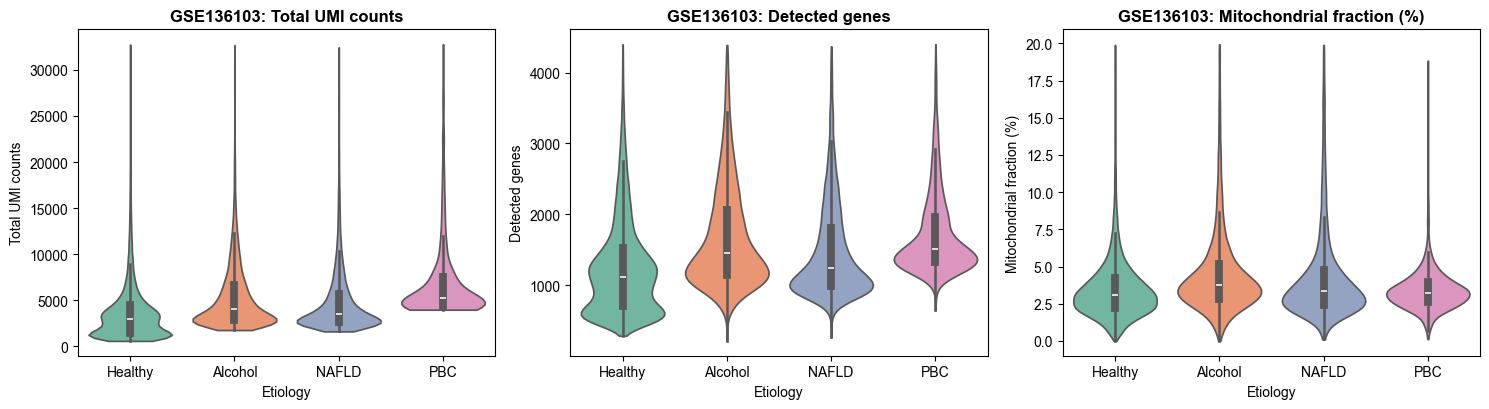

In [ ]:
# QC thresholds (MIN_GENES = 200 preserves low-RNA quiescent HSCs)
MIN_GENES = 200
MAX_MT_PCT = 20.0
UPPER_QUANTILE = 0.995

adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

upper_genes = np.quantile(adata.obs["n_genes_by_counts"], UPPER_QUANTILE)
upper_counts = np.quantile(adata.obs["total_counts"], UPPER_QUANTILE)

n_raw_cells = adata.n_obs
qc_mask = (
    (adata.obs["n_genes_by_counts"] >= MIN_GENES) &
    (adata.obs["n_genes_by_counts"] <= upper_genes) &
    (adata.obs["total_counts"] <= upper_counts) &
    (adata.obs["pct_counts_mt"] <= MAX_MT_PCT)
)

adata = adata[qc_mask].copy()
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["counts"] = adata.X.copy()

print(f"QC SUMMARY: Retained {adata.n_obs:,} / {n_raw_cells:,} cells ({100*adata.n_obs/n_raw_cells:.2f}%) and {adata.n_vars:,} genes.")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
qc_metrics_plot = [
    ("total_counts", "Total UMI counts"),
    ("n_genes_by_counts", "Detected genes"),
    ("pct_counts_mt", "Mitochondrial fraction (%)")
]
for ax, (col, title) in zip(axes, qc_metrics_plot):
    sns.violinplot(
        data=adata.obs, x="etiology", y=col, 
        order=["Healthy", "Alcohol", "NAFLD", "PBC"],
        palette="Set2", inner="box", cut=0, ax=ax
    )
    ax.set_title(f"{DATASET_ID}: {title}", fontweight="bold")
    ax.set_xlabel("Etiology")
    ax.set_ylabel(title)

In [ ]:
# Run Scrublet independently per 10x library (sample_id) to respect droplet formation physics
adata.obs["doublet_score"] = 0.0
adata.obs["predicted_doublet"] = False

for sid in adata.obs["sample_id"].unique():
    mask = (adata.obs["sample_id"] == sid).values
    X_sub = adata[mask].layers["counts"]
    n_c = X_sub.shape[0]
    
    scrub = scr.Scrublet(X_sub, random_state=RANDOM_STATE)
    scores, preds = scrub.scrub_doublets(
        min_counts=2, min_cells=3, min_gene_variability_pctl=85,
        n_prin_comps=min(30, n_c - 1), verbose=False
    )
    if preds is None:
        thr = np.quantile(scores, 0.99)
        preds = scores >= thr
        
    adata.obs.loc[mask, "doublet_score"] = scores
    adata.obs.loc[mask, "predicted_doublet"] = preds
    print(f"sample {sid} ({n_c} cells): finding {int(preds.sum())} doublets ({100*np.mean(preds):.2f}%)")

n_before_scrub = adata.n_obs
adata = adata[~adata.obs["predicted_doublet"]].copy()
adata.layers["counts"] = adata.X.copy()
print(f"SCRUBLET: remove {n_before_scrub - adata.n_obs} / {n_before_scrub} cells ({100*(n_before_scrub - adata.n_obs)/n_before_scrub:.2f}%)")
print(f"Remaining clean cells: {adata.n_obs:,} cells × {adata.n_vars:,} genes")

# Save post-QC singlet checkpoint
adata.write_h5ad(os.path.join(OUT_DIR, f"{DATASET_ID}_QC.h5ad"))

sample GSM4041150 (1841 cells): finding 18 doublets (0.98%)
sample GSM4041151 (805 cells): finding 1 doublets (0.12%)
sample GSM4041152 (366 cells): finding 3 doublets (0.82%)
sample GSM4041153 (6569 cells): finding 12 doublets (0.18%)
sample GSM4041154 (4675 cells): finding 88 doublets (1.88%)
sample GSM4041155 (3271 cells): finding 62 doublets (1.90%)
sample GSM4041156 (2984 cells): finding 44 doublets (1.47%)
sample GSM4041157 (1017 cells): finding 13 doublets (1.28%)
sample GSM4041158 (4900 cells): finding 120 doublets (2.45%)
sample GSM4041159 (3244 cells): finding 45 doublets (1.39%)
sample GSM4041160 (5093 cells): finding 36 doublets (0.71%)
sample GSM4041161 (2230 cells): finding 17 doublets (0.76%)
sample GSM4041162 (1507 cells): finding 3 doublets (0.20%)
sample GSM4041163 (1757 cells): finding 19 doublets (1.08%)
sample GSM4041164 (3251 cells): finding 45 doublets (1.38%)
sample GSM4041165 (3494 cells): finding 34 doublets (0.97%)
sample GSM4041166 (1862 cells): finding 6 do

## 6. Whole-Liver Normalization, Feature Selection & Unsupervised Clustering
Perform library-size normalization (`target_sum = 1e4`), log1p transformation, highly variable gene selection (`n_top_genes = 3,000` excluding mitochondrial, ribosomal, and hemoglobin genes), PCA (`40 PCs`), kNN graph construction, UMAP embedding, and Leiden clustering.

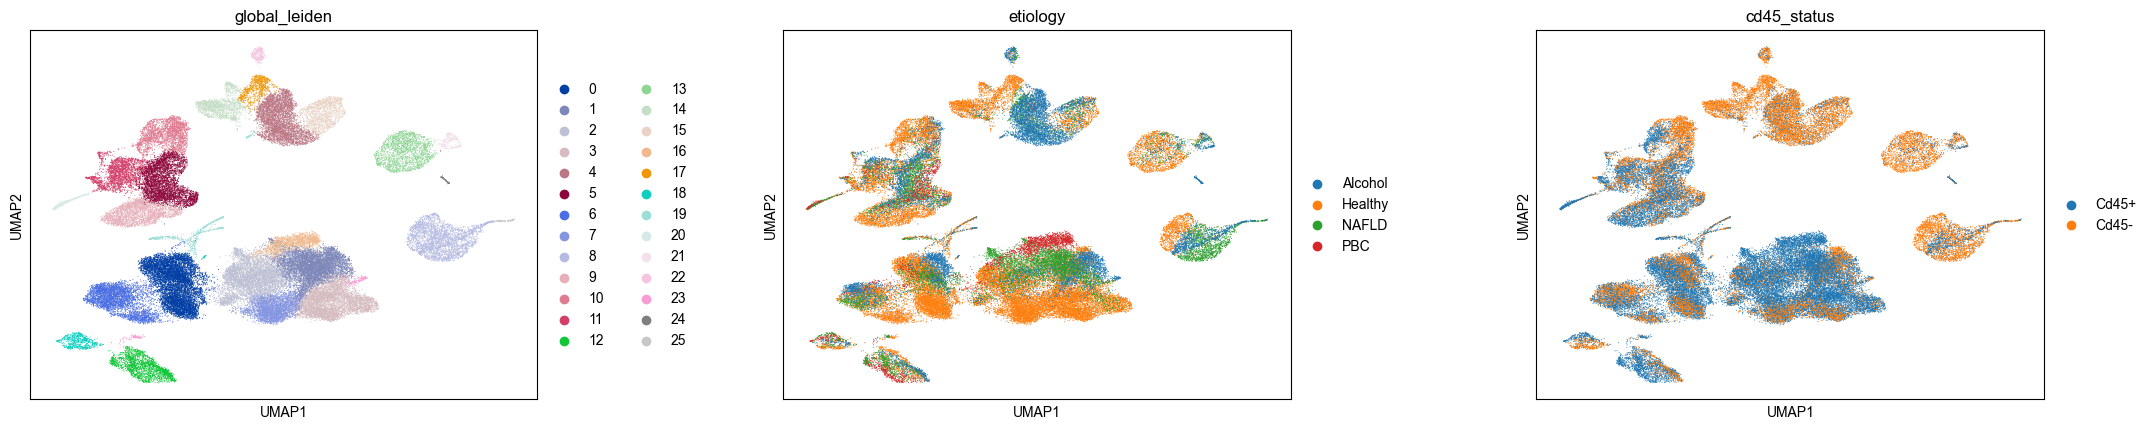

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

# Mask technical and ambient genes prior to HVG selection
gene_names = adata.var_names.str.upper()
blacklist_mask = (
    gene_names.str.startswith(("MT-", "RPS", "RPL", "HB")) |
    gene_names.isin(["MALAT1", "NEAT1"])
)

sc.pp.highly_variable_genes(adata, n_top_genes=3000, flavor="seurat")
adata.var.loc[blacklist_mask, "highly_variable"] = False

adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, svd_solver="arpack", n_comps=40, random_state=RANDOM_STATE)

adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"].copy()
del adata_hvg
gc.collect()

sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, random_state=RANDOM_STATE)
sc.tl.umap(adata, random_state=RANDOM_STATE)
sc.tl.leiden(adata, resolution=0.8, key_added="leiden_0.8", random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sc.pl.umap(adata, color="leiden_0.8", legend_loc="on data", title=f"{DATASET_ID}: Leiden (res=0.8)", ax=axes[0], show=False)
sc.pl.umap(adata, color="disease_group", title=f"{DATASET_ID}: Disease Group", ax=axes[1], show=False)
sc.pl.umap(adata, color="etiology", title=f"{DATASET_ID}: Etiology", ax=axes[2], show=False)

## 7. Tier 1 Purification — Pan-Liver Mesenchymal Lineage Isolation
Score all 6 major hepatic lineages (`HSC_Mesenchymal`, `Hepatocyte`, `Cholangiocyte`, `Endothelial`, `Myeloid`, `Lymphoid`) using standardized Z-scores and isolate candidate mesenchymal clusters ($\bar{Z}_{\text{Mesenchymal}} > 1.0$ with $>0.5\text{ SD}$ margin over all non-mesenchymal lineages; $n = 2,297$ mesenchymal cells).

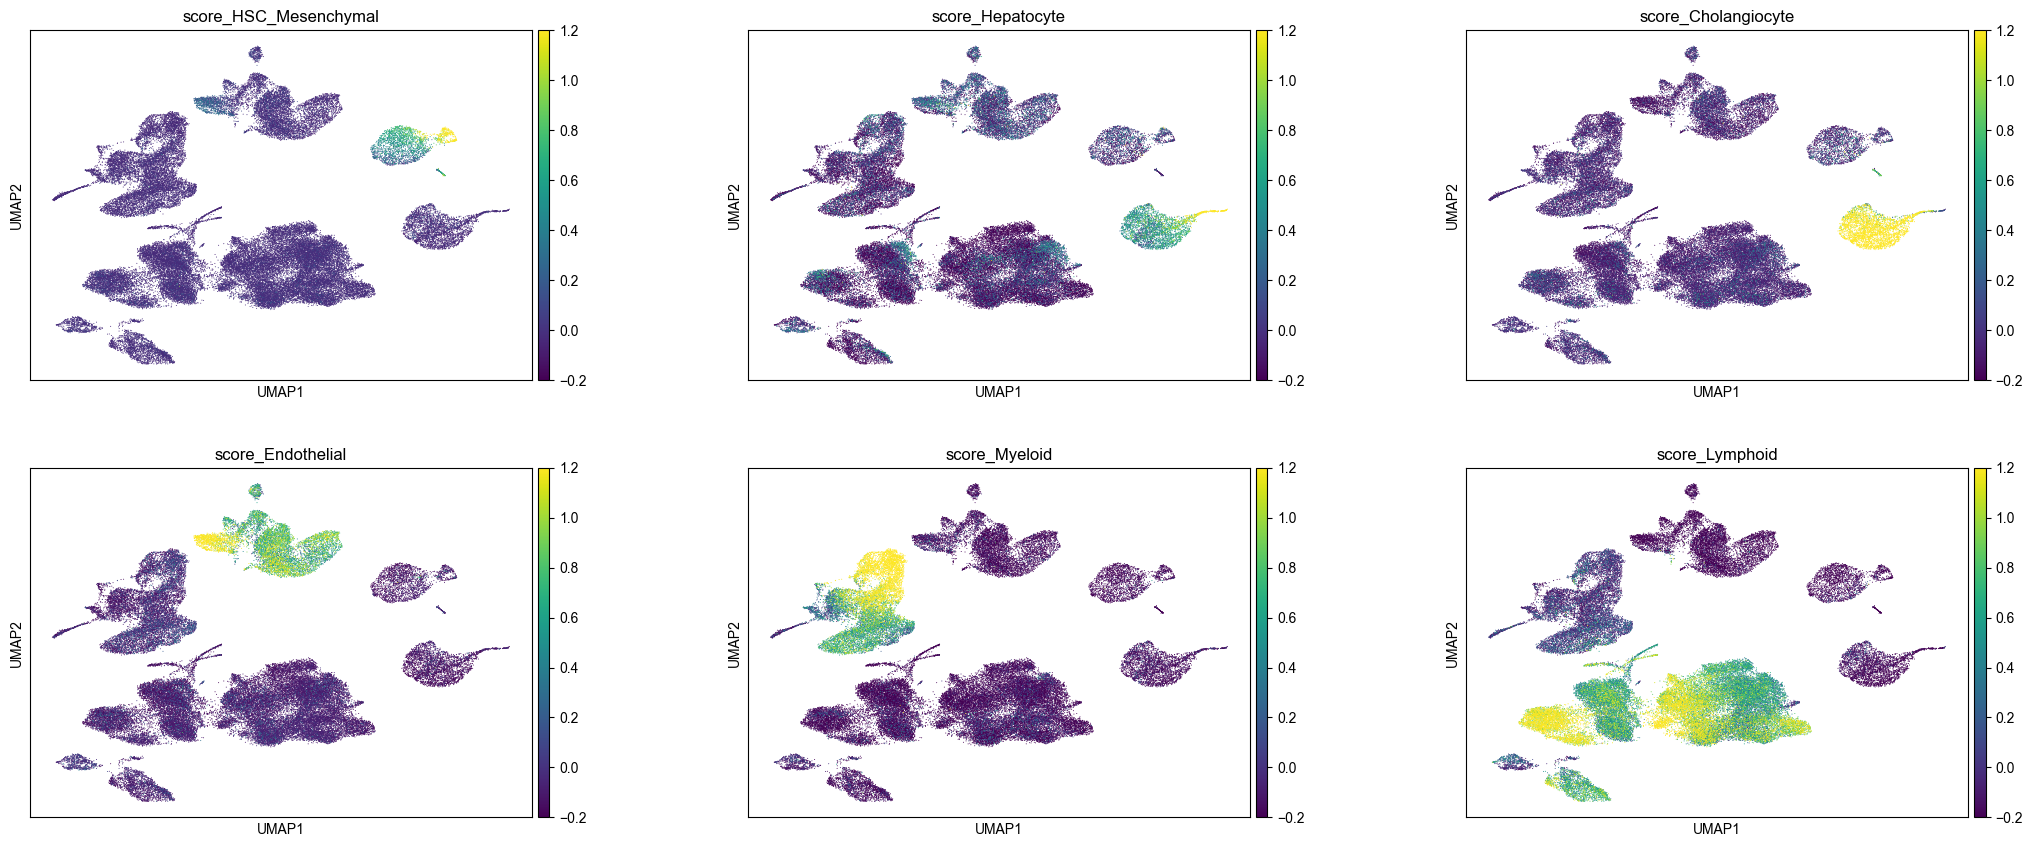

Selected Mesenchymal Leiden clusters: ['13', '21', '24']
Extracted Mesenchymal compartment: 2,297 / 59,332 cells (3.87%)


In [ ]:
lineage_markers = {
    "HSC_Mesenchymal": ["LRAT", "RELN", "RGS5", "COLEC11", "COL1A1", "COL1A2", "COL3A1", "ACTA2", "PDGFRB", "DCN", "LUM", "TAGLN", "CYGB"],
    "Hepatocyte":      ["ALB", "TTR", "APOA1", "APOA2", "APOC3", "CYP3A4", "CYP2E1", "HNF4A", "ASGR1", "FGB"],
    "Cholangiocyte":   ["EPCAM", "KRT19", "KRT7", "CFTR", "SOX9", "CLDN4", "MMP7", "TROP2"],
    "Endothelial":     ["PECAM1", "VWF", "CDH5", "FLT1", "KDR", "CLDN5", "STAB2", "LYVE1", "FCGR2B"],
    "Myeloid":         ["CD68", "LYZ", "CSF1R", "CD14", "FCGR3A", "MARCO", "CD163", "C1QA", "C1QB", "AIF1"],
    "Lymphoid":        ["PTPRC", "CD3D", "CD3E", "CD2", "TRAC", "NKG7", "GNLY", "CD79A", "MS4A1", "MZB1"]
}

raw_genes = adata.raw.var_names
score_cols = []

for lin, genes in lineage_markers.items():
    valid_g = [g for g in genes if g in raw_genes]
    sc.tl.score_genes(adata, gene_list=valid_g, score_name=f"raw_{lin}", use_raw=True, random_state=RANDOM_STATE)
    col_z = f"Z_{lin}"
    adata.obs[col_z] = StandardScaler().fit_transform(adata.obs[[f"raw_{lin}"]])
    score_cols.append(col_z)

cluster_Profiles = adata.obs.groupby("leiden_0.8")[score_cols].mean()
non_mes_cols = [c for c in score_cols if c != "Z_HSC_Mesenchymal"]
max_other = cluster_Profiles[non_mes_cols].max(axis=1)

# Tier 1 cluster gating rule: Z_Mesenchymal > 1.0 and > max(non-mesenchymal) + 0.5 SD
mes_clusters = cluster_Profiles[
    (cluster_Profiles["Z_HSC_Mesenchymal"] > 1.0) &
    ((cluster_Profiles["Z_HSC_Mesenchymal"] - max_other) > 0.5)
].index.tolist()

adata.obs["is_mesenchymal_cluster"] = adata.obs["leiden_0.8"].isin(mes_clusters)
adata_mes = adata[adata.obs["is_mesenchymal_cluster"]].copy()

## 8. Tier 2 Purification — Reciprocal Z-Score Gating, Pre-Integration 4-State Scoring & Export
Execute within-mesenchymal reciprocal Z-score gating to exclude vascular smooth muscle cells (`VSMC_Pericyte`: $z_{\text{VSMC}} > 1.0 \land z_{\text{VSMC}} > z_{\text{HSC}}$), portal fibroblasts (`Portal_Fibroblast`: $z_{\text{PF}} > 1.0 \land z_{\text{PF}} > z_{\text{HSC}}$), mesothelial cells, and non-mesenchymal doublets, enforcing strict zero-UMI gates (`PTPRC == 0`, `EPCAM == 0`). Perform pre-integration 4-state HSC classification (`qHSC`, `A1_Myofibroblast`, `A2_Fibrogenic`, `Inflammatory_HSC`) and export the purified dataset (`GSE136103_HSC_clean.h5ad`)

mes_lineage_class
HSC                   1402
Contam_Mesothelial     316
VSMC_Pericyte          314
Portal_Fibroblast      265
Name: count, dtype: int64
---------------------------------------------------------------------------
 Hepatic Stella Cells : 1,396 cells (60.8% Mesenchymal, 2.35% Whole Liver)
    • Inclusive HSCs           : 2,067 cells
    • Stringent HSCs           : 803 cells
    • VSMC / Pericytes remove : 367 cells
    • Portal Fibroblasts remove : 298 cells


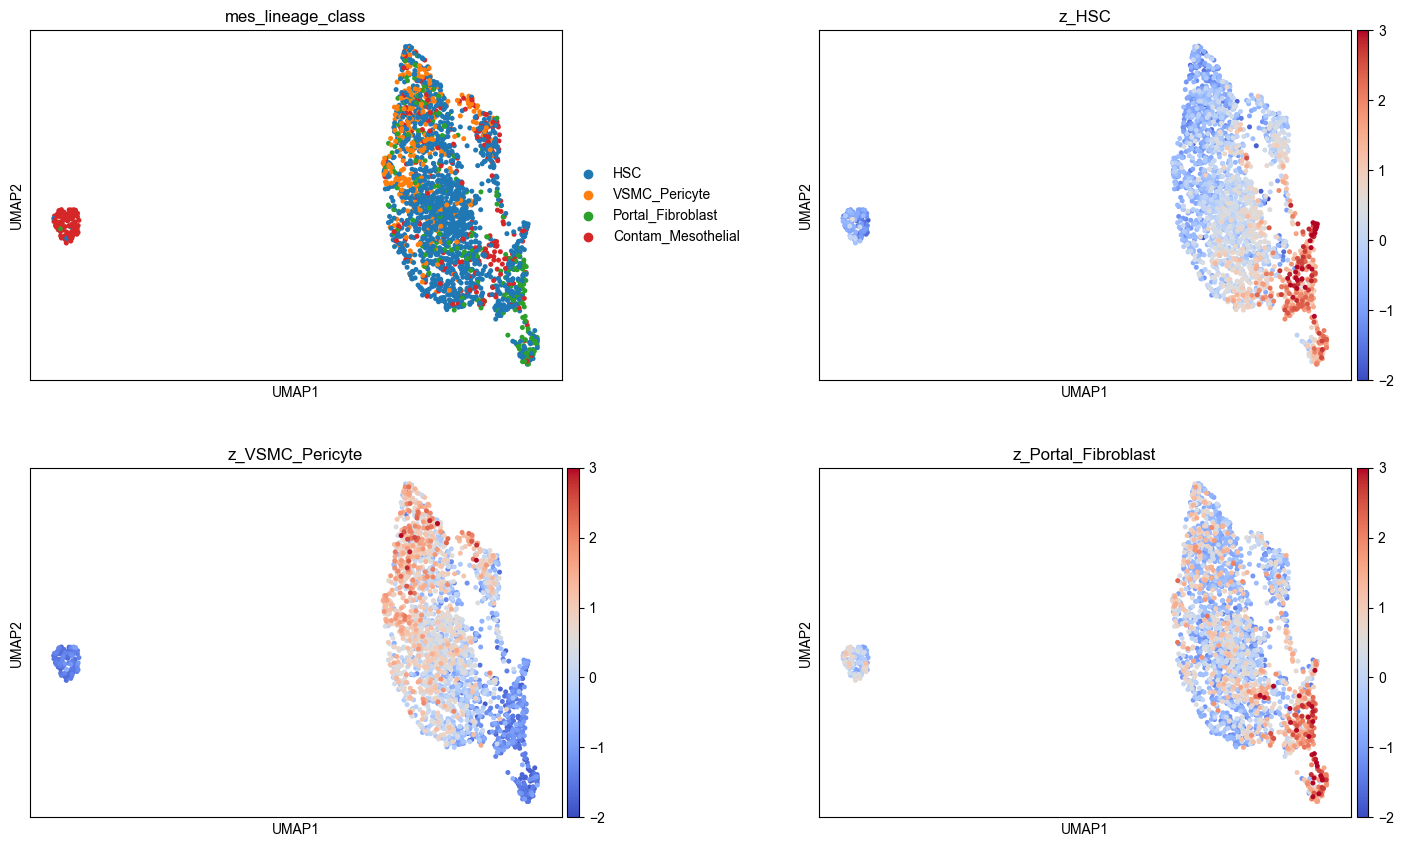

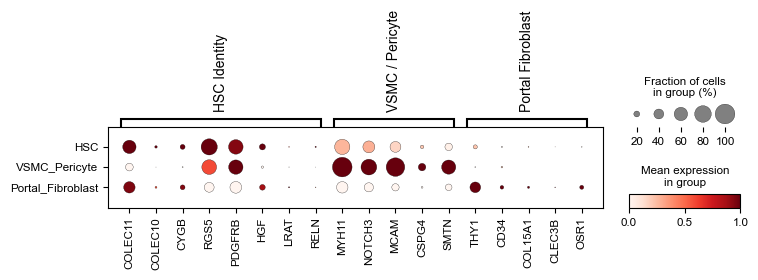

In [ ]:
adata_mes.X = adata_mes.layers["log1p_norm"].copy()
sc.pp.highly_variable_genes(adata_mes, n_top_genes=2000, flavor="seurat", subset=False)

adata_mes_hvg = adata_mes[:, adata_mes.var["highly_variable"]].copy()
sc.pp.scale(adata_mes_hvg, max_value=10)
sc.tl.pca(adata_mes_hvg, n_comps=25, svd_solver="arpack", random_state=RANDOM_STATE)
adata_mes.obsm["X_pca"] = adata_mes_hvg.obsm["X_pca"].copy()
del adata_mes_hvg

sc.pp.neighbors(adata_mes, n_neighbors=15, n_pcs=20, random_state=RANDOM_STATE)
sc.tl.umap(adata_mes, random_state=RANDOM_STATE)
sc.tl.leiden(adata_mes, resolution=0.8, key_added="mes_subcluster", random_state=RANDOM_STATE)

PANELS_GATING = {
    "HSC_Core": [
        "LRAT", "RBP1", "CYGB", "RELN", "COLEC11", "COLEC10", "ACTA2", "TAGLN", "CNN1",
        "DCN", "LUM", "COL1A1", "COL1A2", "COL3A1", "RGS5", 
        "DES", "GFAP", "PDGFRB", "SPARC", "IGFBP3","TIMP1"
    ],
    "VSMC_Pericyte": [
        "MYH11", "NOTCH3", "CSPG4", "MCAM", "SMTN", "MYLK"
    ],
    "Portal_Fibroblast": [
        "CLEC3B", "CD34", "COL15A1", "THY1", "OSR1", "MFAP4"
    ],
    "Mesothelial": [
        "UPK3B", "MSLN", "UPK1B"
    ],
    "Lineage_Contam": [
        "PTPRC", "LYZ", "CD68", "PECAM1", "VWF", "KDR", "ALB", "EPCAM", "TTR"
    ]
}


for p_name, p_genes in PANELS_GATING.items():
    valid_g = [g for g in p_genes if g in adata_mes.var_names]
    sc.tl.score_genes(
        adata_mes, gene_list=valid_g, score_name=f"score_{p_name}", 
        random_state=RANDOM_STATE, use_raw=False
    )


def calc_zscore(series):
    sd = series.std(ddof=0)
    return (series - series.mean()) / (sd if sd > 0 else 1.0)

adata_mes.obs["z_HSC"]               = calc_zscore(adata_mes.obs["score_HSC_Core"])
adata_mes.obs["z_VSMC_Pericyte"]     = calc_zscore(adata_mes.obs["score_VSMC_Pericyte"])
adata_mes.obs["z_Portal_Fibroblast"] = calc_zscore(adata_mes.obs["score_Portal_Fibroblast"])
adata_mes.obs["z_Mesothelial"]       = calc_zscore(adata_mes.obs["score_Mesothelial"])
adata_mes.obs["z_Lineage_Contam"]    = calc_zscore(adata_mes.obs["score_Lineage_Contam"])


z_hsc   = adata_mes.obs["z_HSC"]
z_vsmc  = adata_mes.obs["z_VSMC_Pericyte"]
z_pf    = adata_mes.obs["z_Portal_Fibroblast"]
z_meso  = adata_mes.obs["z_Mesothelial"]
z_contam= adata_mes.obs["z_Lineage_Contam"]

raw_X = adata_mes.layers["counts"]
gene_to_idx = {g: i for i, g in enumerate(adata_mes.var_names)}
def get_raw_count(g):
    return raw_X[:, gene_to_idx[g]].toarray().ravel() if g in gene_to_idx else np.zeros(adata_mes.n_obs)

is_vsmc_leak  = (z_vsmc > 1.0) & (z_vsmc > z_hsc)
is_pf_leak    = (z_pf > 1.0) & (z_pf > z_hsc)
is_meso_leak  = (z_meso > 1.5) & (z_meso > z_hsc)
is_other_leak = (z_contam > 1.8) | (get_raw_count("PTPRC") > 0) | (get_raw_count("EPCAM") > 0)

mes_class = pd.Series("HSC", index=adata_mes.obs_names)
mes_class.loc[is_vsmc_leak]  = "VSMC_Pericyte"
mes_class.loc[is_pf_leak]    = "Portal_Fibroblast"
mes_class.loc[is_meso_leak | is_other_leak] = "Contam_Mesothelial"
adata_mes.obs["mes_lineage_class"] = pd.Categorical(
    mes_class, categories=["HSC", "VSMC_Pericyte", "Portal_Fibroblast", "Contam_Mesothelial"]
)


hsc_clean_bool = (adata_mes.obs["mes_lineage_class"] == "HSC") & (adata_mes.obs["etiology"] != "PBC")
adata_mes.obs["is_HSC_clean"] = hsc_clean_bool.values


adata_mes.obs["is_HSC_primary"]   = hsc_clean_bool.values
adata_mes.obs["is_HSC_inclusive"] = (~is_other_leak & (adata_mes.obs["etiology"] != "PBC")).values
adata_mes.obs["is_HSC_stringent"] = (hsc_clean_bool & (z_vsmc < 0.5) & (z_pf < 0.5)).values

n_clean = int(adata_mes.obs["is_HSC_clean"].sum())
n_mes   = adata_mes.n_obs
print("=" * 75)
print(adata_mes.obs["mes_lineage_class"].value_counts())
print("-" * 75)
print(f" Hepatic Stella Cells : {n_clean:,} cells ({100*n_clean/n_mes:.1f}% Mesenchymal, {100*n_clean/adata.n_obs:.2f}% Whole Liver)")
print(f"    • Inclusive HSCs           : {int(adata_mes.obs['is_HSC_inclusive'].sum()):,} cells")
print(f"    • Stringent HSCs           : {int(adata_mes.obs['is_HSC_stringent'].sum()):,} cells")
print(f"    • VSMC / Pericytes remove : {int(is_vsmc_leak.sum()):,} cells")
print(f"    • Portal Fibroblasts remove : {int(is_pf_leak.sum()):,} cells")
print("=" * 75)


sc.pl.umap(
    adata_mes, 
    color=["mes_lineage_class", "z_HSC", "z_VSMC_Pericyte", "z_Portal_Fibroblast"],
    ncols=2, wspace=0.35, cmap="coolwarm", vmin=-2.0, vmax=3.0, show=False
)
savefig(f"{DATASET_ID}_Fig4_Mesenchymal_Disentanglement_UMAP.png")

adata_mes_plot = adata_mes[adata_mes.obs["mes_lineage_class"].isin(["HSC", "VSMC_Pericyte", "Portal_Fibroblast"])].copy()

lineage_dotplot_dict = {
    "HSC Identity":      [g for g in ["COLEC11", "COLEC10", "CYGB", "RGS5", "PDGFRB", "HGF", "LRAT", "RELN"] if g in adata_mes_plot.var_names],
    "VSMC / Pericyte":   [g for g in ["MYH11", "NOTCH3", "MCAM", "CSPG4", "SMTN"] if g in adata_mes_plot.var_names],
    "Portal Fibroblast": [g for g in ["THY1", "CD34", "COL15A1", "CLEC3B", "OSR1"] if g in adata_mes_plot.var_names]}

sc.pl.dotplot(
    adata_mes_plot, var_names=lineage_dotplot_dict, groupby="mes_lineage_class",
    standard_scale="var", cmap="Reds", show=False)

In [ ]:
adata_hsc = adata_mes[adata_mes.obs["is_HSC_clean"]].copy()
adata_hsc.X = adata_hsc.layers["log1p_norm"].copy()

HSC_STATE_PANELS = {
    "qHSC": [
        "LRAT", "RBP1", "RELN", "CYGB", "COLEC11", "COLEC10", 
        "VIPR1", "HHIP", "NGFR", "GFAP", "PPARG", "ADGRL3"
    ],
    "A1_HSC": [
        "ACTA2", "TAGLN", "MYL9", "TPM2", "CNN1", "CALD1", "MYLK", "VCL"
    ],
    "A2_HSC": [
        "COL1A1", "COL1A2", "COL3A1", "LUM", "TIMP1", "SERPINE1", 
        "SPARC", "FN1", "VCAN", "POSTN", "LOXL2", "MMP2"
    ],
    "INF_HSC": [
        "CCL2", "CXCL8", "CXCL1", "CXCL2", "IL6", "ICAM1", 
        "NFKBIA", "TNFAIP3", "CCL20", "SOD2", "IRF1"
    ]
}

sc.pp.highly_variable_genes(adata_hsc, n_top_genes=1500, flavor="seurat", subset=False)
adata_hsc_hvg = adata_hsc[:, adata_hsc.var["highly_variable"]].copy()
sc.pp.scale(adata_hsc_hvg, max_value=10)
sc.tl.pca(adata_hsc_hvg, n_comps=20, svd_solver="arpack", random_state=RANDOM_STATE)
adata_hsc.obsm["X_pca"] = adata_hsc_hvg.obsm["X_pca"].copy()
del adata_hsc_hvg

sc.pp.neighbors(adata_hsc, n_neighbors=15, n_pcs=15, random_state=RANDOM_STATE)
sc.tl.umap(adata_hsc, min_dist=0.3, random_state=RANDOM_STATE)
sc.tl.leiden(adata_hsc, resolution=0.6, key_added="hsc_leiden", random_state=RANDOM_STATE)

# Module Score 4 state & Normalized Z-score + kNN 
raw_state_cols = []
for st_name, genes in HSC_STATE_PANELS.items():
    valid_g = [g for g in genes if g in adata_hsc.var_names]
    col = f"score_{st_name}"
    sc.tl.score_genes(adata_hsc, gene_list=valid_g, score_name=col, use_raw=False, ctrl_size=50, random_state=RANDOM_STATE)
    raw_state_cols.append(col)

z_state_cols = ["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"]
Z_raw = StandardScaler().fit_transform(adata_hsc.obs[raw_state_cols].values)

conn = adata_hsc.obsp["connectivities"].copy()
row_sums = np.array(conn.sum(axis=1)).ravel()
row_sums[row_sums == 0] = 1.0
W = sp.diags(1.0 / row_sums) @ conn
Z_smoothed = 0.70 * Z_raw + 0.30 * (W @ Z_raw)

adata_hsc.obs[z_state_cols] = Z_smoothed
adata_hsc.obs["HSC_state"] = adata_hsc.obs[z_state_cols].idxmax(axis=1)
adata_hsc.obs["HSC_state"] = pd.Categorical(
    adata_hsc.obs["HSC_state"], categories=["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"], ordered=True
)

print("=" * 75)
print(f"4 STATES ({DATASET_ID}: n = {adata_hsc.n_obs:,} cells) ===")
state_counts = adata_hsc.obs["HSC_state"].value_counts()
for st in ["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"]:
    cnt = state_counts.get(st, 0)
    print(f"  • {st:<8}: {cnt:>4} cells ({100*cnt/adata_hsc.n_obs:>5.2f}%)")

print("\n ETIOLOGY × HSC STATE (cell counts) ")
ct_counts = pd.crosstab(adata_hsc.obs["etiology"], adata_hsc.obs["HSC_state"], margins=True)
print(ct_counts)

print("\n Etiology-based percentage of 4 states (%) ")
ct_pct = pd.crosstab(adata_hsc.obs["etiology"], adata_hsc.obs["HSC_state"], normalize="index") * 100
ct_pct = ct_pct.reindex([e for e in ["Healthy", "Alcohol", "NAFLD"] if e in ct_pct.index])
print(ct_pct.round(2))

donor_audit = pd.crosstab(
    [adata_hsc.obs["etiology"], adata_hsc.obs["patient_id"]], 
    adata_hsc.obs["HSC_state"], margins=True, margins_name="Total_HSCs"
)
donor_audit.to_csv(os.path.join(OUT_DIR, f"{DATASET_ID}_Donor_Level_HSC_Audit.csv"))

4 STATES (GSE136103: n = 1,396 cells) ===
  • qHSC    :  307 cells (21.99%)
  • A1_HSC  :  638 cells (45.70%)
  • A2_HSC  :  174 cells (12.46%)
  • INF_HSC :  277 cells (19.84%)

 ETIOLOGY × HSC STATE (cell counts) 
HSC_state  qHSC  A1_HSC  A2_HSC  INF_HSC   All
etiology                                      
Alcohol      38      65     104       15   222
Healthy     217     505      25      233   980
NAFLD        52      68      45       29   194
All         307     638     174      277  1396

 Etiology-based percentage of 4 states (%) 
HSC_state   qHSC  A1_HSC  A2_HSC  INF_HSC
etiology                                 
Healthy    22.14   51.53    2.55    23.78
Alcohol    17.12   29.28   46.85     6.76
NAFLD      26.80   35.05   23.20    14.95

 DONOR-LEVEL REPLICATES 
HSC_state              qHSC  A1_HSC  A2_HSC  INF_HSC  Total_HSCs
etiology   patient_id                                           
Alcohol    cirrhotic2    22      20      22        6          70
           cirrhotic3    1

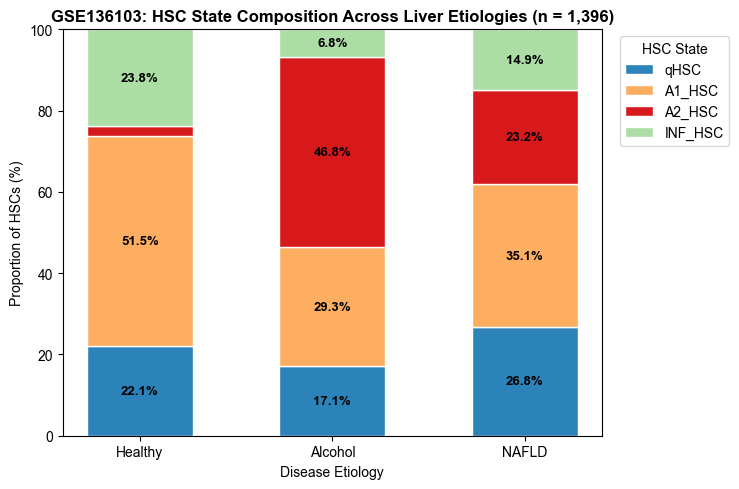

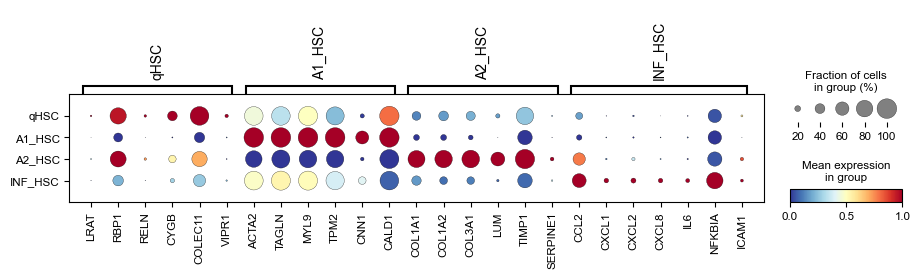

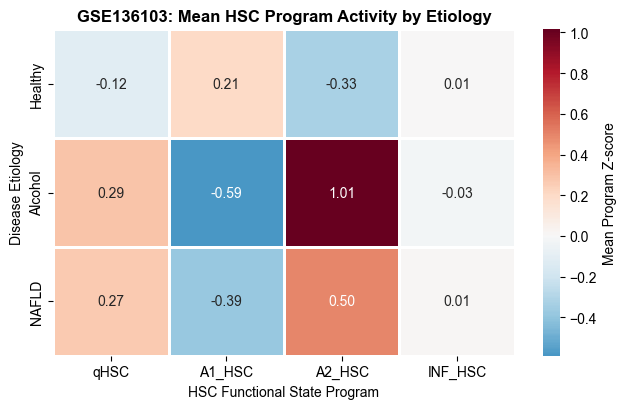

In [ ]:
state_palette = {"qHSC": "#2b83ba", "A1_HSC": "#fdae61", "A2_HSC": "#d7191c", "INF_HSC": "#abdda4"}
# Stacked Barplot 
fig, ax = plt.subplots(figsize=(7.5, 5))
bottom = np.zeros(len(ct_pct))
for st in ["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"]:
    if st in ct_pct.columns:
        vals = ct_pct[st].values
        ax.bar(ct_pct.index, vals, bottom=bottom, label=st, color=state_palette[st], edgecolor="white", width=0.55)
        for i, v in enumerate(vals):
            if v >= 4.0:
                ax.text(i, bottom[i] + v / 2, f"{v:.1f}%", ha="center", va="center", fontsize=9.5, fontweight="bold", color="black")
        bottom += vals

ax.set_ylim(0, 100)
ax.set_ylabel("Proportion of HSCs (%)")
ax.set_xlabel("Disease Etiology")
ax.set_title(f"{DATASET_ID}: HSC State Composition Across Liver Etiologies (n = {adata_hsc.n_obs:,})", fontweight="bold")
ax.legend(title="HSC State", bbox_to_anchor=(1.02, 1), loc="upper left")

# Grouped Dotplot
state_marker_dict = {
    "qHSC":    [g for g in ["LRAT", "RBP1", "RELN", "CYGB", "COLEC11", "VIPR1"] if g in adata_hsc.var_names],
    "A1_HSC":  [g for g in ["ACTA2", "TAGLN", "MYL9", "TPM2", "CNN1", "CALD1"] if g in adata_hsc.var_names],
    "A2_HSC":  [g for g in ["COL1A1", "COL1A2", "COL3A1", "LUM", "TIMP1", "SERPINE1"] if g in adata_hsc.var_names],
    "INF_HSC": [g for g in ["CCL2", "CXCL1", "CXCL2", "CXCL8", "IL6", "NFKBIA", "ICAM1"] if g in adata_hsc.var_names]
}
sc.pl.dotplot(
    adata_hsc, var_names=state_marker_dict, groupby="HSC_state",
    standard_scale="var", cmap="RdYlBu_r", show=False)

# Heatmap 
eti_z_means = adata_hsc.obs.groupby("etiology", observed=True)[z_state_cols].mean().reindex(["Healthy", "Alcohol", "NAFLD"])
fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.heatmap(
    eti_z_means, annot=True, fmt=".2f", cmap="RdBu_r", center=0, 
    linewidths=1, cbar_kws={"label": "Mean Program Z-score"}, ax=ax
)
ax.set_title(f"{DATASET_ID}: Mean HSC Program Activity by Etiology", fontweight="bold")
ax.set_xlabel("HSC Functional State Program")
ax.set_ylabel("Disease Etiology")

adata_hsc.X = adata_hsc.layers["counts"].copy()
out_h5ad = os.path.join(OUT_DIR, f"{DATASET_ID}_HSC_clean.h5ad")
adata_hsc.write_h5ad(out_h5ad)